# 03 — Exploratory Data Analysis
**Workforce Pulse · Phase 4**

Answers business questions Q1–Q5 **before** any modelling, across five dimensions:
1. Workforce overview · 2. Attrition · 3. Compensation · 4. Satisfaction & working conditions · 5. Career development

**Method rules**
- Every rate is shown with its **group size (n)** and a **95 % Wilson confidence interval**.
- Associations are tested (chi-square / Mann-Whitney) and sized (Cramér's V / rank-biserial r) — significance alone
  is not importance.
- Where a pattern could be explained by another variable (e.g. pay ↔ seniority), we run a **controlled comparison**.
- Everything is association, **not causation**.

## 0. Setup and helpers

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "data"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

from scipy import stats
from statsmodels.stats.proportion import proportion_confint

df = pd.read_csv(DATA / "processed" / "hr_featured.csv")
ORDERS = {
    "TenureBand": ["New (0-2y)", "Early (3-5y)", "Mid (6-10y)", "Long (11y+)"],
    "AgeBand": ["Under 25", "25-34", "35-44", "45-54", "55+"],
    "IncomeBand": ["<5k", "5k-10k", "10k-15k", "15k+"],
    "YearsSincePromotionBand": ["0-1y", "2-4y", "5y+"],
    "BusinessTravel": ["Non-Travel", "Travel_Rarely", "Travel_Frequently"],
}
OVERALL = df.AttritionFlag.mean()
LEFT, STAY = "#DD8452", "#4C72B0"


def rate_table(data, col, order=None):
    g = data.groupby(col, observed=True)["AttritionFlag"].agg(n="count", left="sum")
    g["rate"] = g.left / g.n
    ci = [proportion_confint(l, n, method="wilson") for l, n in zip(g.left, g.n)]
    g["ci_low"], g["ci_high"] = zip(*ci)
    order = order or ORDERS.get(col)
    return g.reindex(order) if order else g.sort_values("rate", ascending=False)


def rate_plot(col, ax, order=None, title=None, data=None):
    t = rate_table(df if data is None else data, col, order)
    x = np.arange(len(t))
    ax.bar(x, t.rate * 100, color=LEFT, alpha=.85)
    ax.errorbar(x, t.rate * 100, yerr=[(t.rate - t.ci_low) * 100, (t.ci_high - t.rate) * 100],
                fmt="none", ecolor="black", capsize=3, lw=1)
    ax.axhline(OVERALL * 100, ls="--", color="grey", lw=1)
    ax.set_xticks(x, [f"{i}\n(n={n})" for i, n in zip(t.index, t.n)], fontsize=8)
    ax.set_ylabel("Attrition rate (%)"); ax.set_title(title or col)
    return t


def cramers_v(col):
    ct = pd.crosstab(df[col], df.AttritionFlag)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    return chi2, p, np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))


def rank_biserial(col):
    a, b = df.loc[df.AttritionFlag == 1, col], df.loc[df.AttritionFlag == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    return p, 1 - 2 * u / (len(a) * len(b)), a.median(), b.median()  # r > 0: leavers lower

## 1. Workforce overview

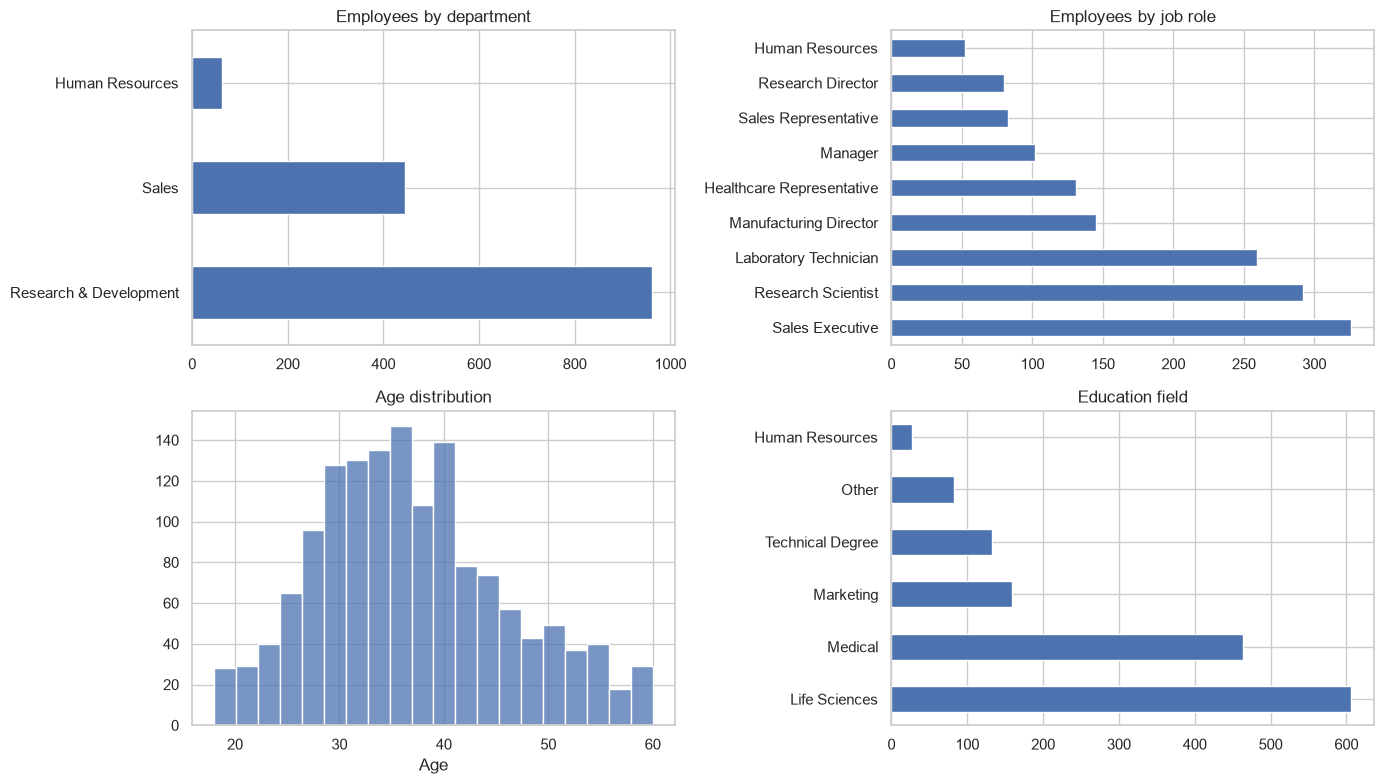

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
df.Department.value_counts().plot.barh(ax=axes[0, 0], color=STAY); axes[0, 0].set_title("Employees by department")
df.JobRole.value_counts().plot.barh(ax=axes[0, 1], color=STAY); axes[0, 1].set_title("Employees by job role")
sns.histplot(df.Age, bins=20, ax=axes[1, 0], color=STAY); axes[1, 0].set_title("Age distribution")
df.EducationField.value_counts().plot.barh(ax=axes[1, 1], color=STAY); axes[1, 1].set_title("Education field")
for a in axes.flat: a.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_workforce_overview.png", dpi=150); plt.show()

In [3]:
overview = {
    "Employees": len(df), "Departments": df.Department.nunique(), "Job roles": df.JobRole.nunique(),
    "Median age": df.Age.median(), "Female share %": round(100 * (df.Gender == "Female").mean(), 1),
    "Median tenure (y)": df.YearsAtCompany.median(), "Median monthly income": df.MonthlyIncome.median(),
    "R&D share %": round(100 * (df.Department == "Research & Development").mean(), 1),
}
pd.Series(overview).to_frame("value")

,value
Employees,1470.0
Departments,3.0
Job roles,9.0
Median age,36.0
Female share %,40.0
Median tenure (y),5.0
Median monthly income,4919.0
R&D share %,65.4


## 2. Attrition analysis
Bars = attrition rate, whiskers = 95 % CI, dashed line = overall rate (16.1 %).

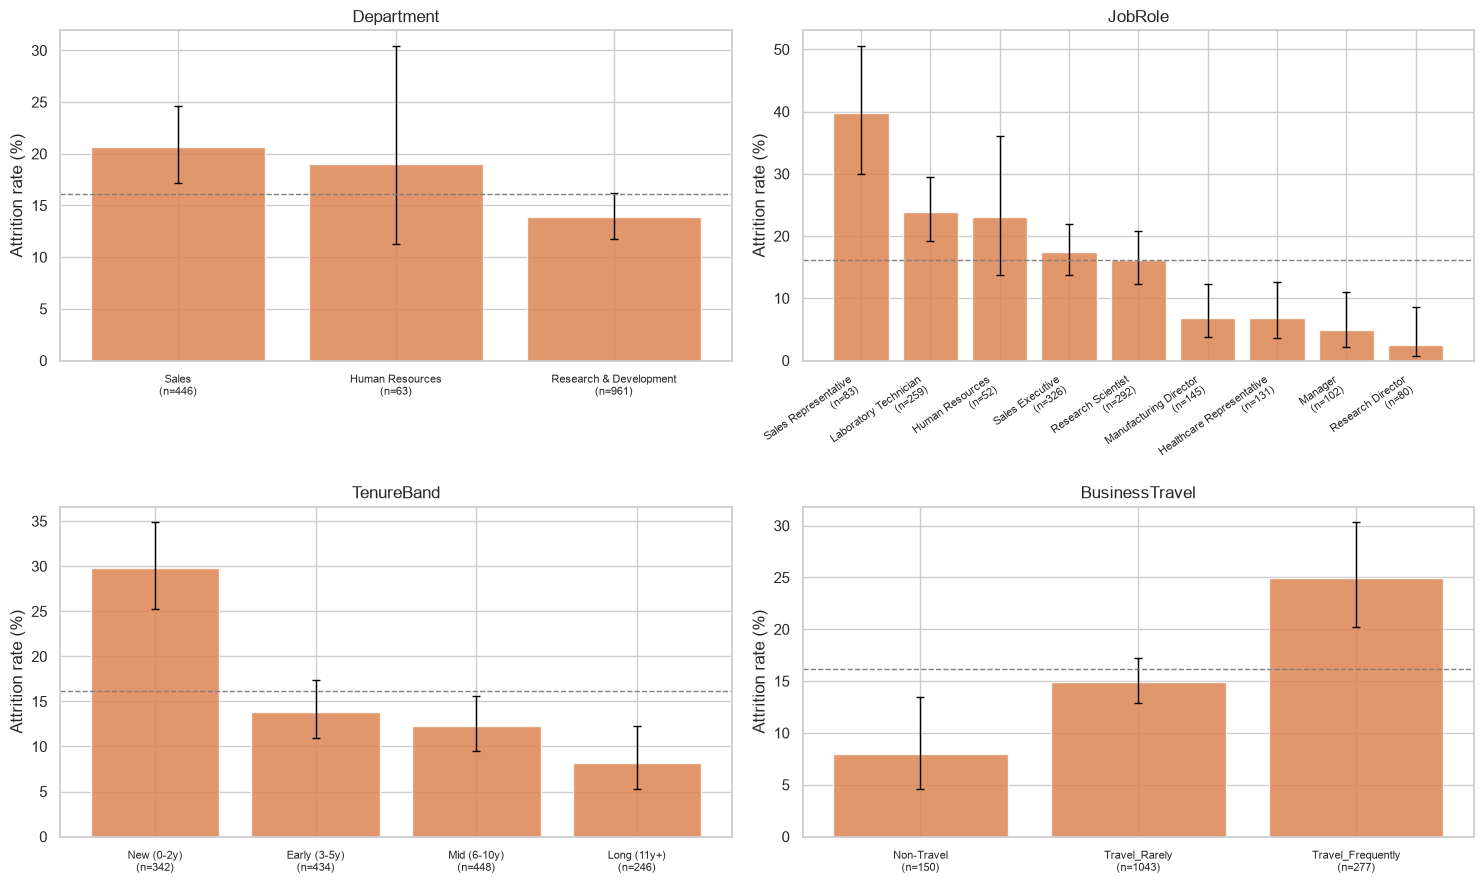

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
t_dept = rate_plot("Department", axes[0, 0])
t_role = rate_plot("JobRole", axes[0, 1]); plt.setp(axes[0, 1].get_xticklabels(), rotation=35, ha="right")
t_ten = rate_plot("TenureBand", axes[1, 0])
t_trav = rate_plot("BusinessTravel", axes[1, 1])
plt.tight_layout(); plt.savefig(FIG_DIR / "04_attrition_breakdowns.png", dpi=150); plt.show()

In [5]:
# Rate vs. volume: which groups contribute most departures?
role = rate_table(df, "JobRole")
role["share_of_leavers_%"] = (100 * role.left / role.left.sum()).round(1)
role.assign(rate=lambda d: (100 * d.rate).round(1)).drop(columns=["ci_low", "ci_high"])

,n,left,rate,share_of_leavers_%
JobRole,,,,
Sales Representative,83,33,39.8,13.9
Laboratory Technician,259,62,23.9,26.2
Human Resources,52,12,23.1,5.1
Sales Executive,326,57,17.5,24.1
Research Scientist,292,47,16.1,19.8
Manufacturing Director,145,10,6.9,4.2
Healthcare Representative,131,9,6.9,3.8
Manager,102,5,4.9,2.1
Research Director,80,2,2.5,0.8


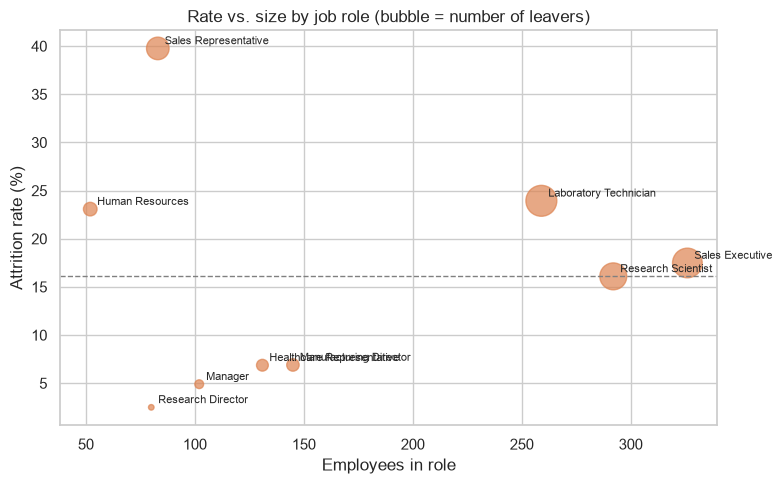

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(role.n, role.rate * 100, s=role.left * 8, color=LEFT, alpha=.7)
for name, r in role.iterrows():
    ax.annotate(name, (r.n, r.rate * 100), fontsize=8, xytext=(5, 3), textcoords="offset points")
ax.axhline(OVERALL * 100, ls="--", color="grey", lw=1)
ax.set_xlabel("Employees in role"); ax.set_ylabel("Attrition rate (%)")
ax.set_title("Rate vs. size by job role (bubble = number of leavers)")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_role_rate_vs_volume.png", dpi=150); plt.show()

## 3. Compensation analysis
**Question:** is attrition higher among lower-income employees, and is that just seniority?

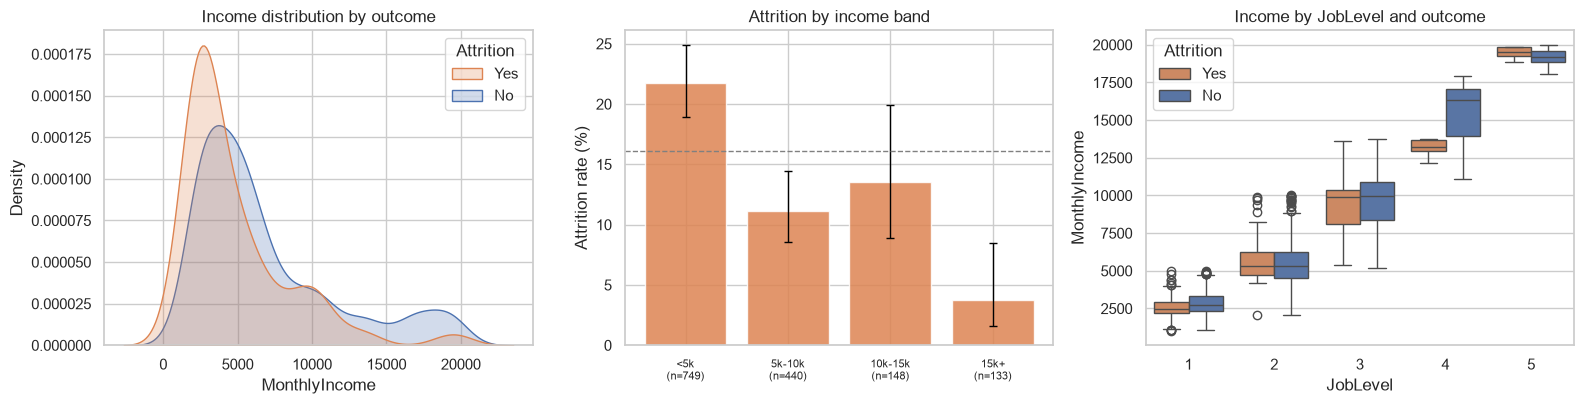

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.kdeplot(data=df, x="MonthlyIncome", hue="Attrition", common_norm=False, fill=True,
            palette={"Yes": LEFT, "No": STAY}, ax=axes[0]); axes[0].set_title("Income distribution by outcome")
rate_plot("IncomeBand", axes[1], title="Attrition by income band")
sns.boxplot(data=df, x="JobLevel", y="MonthlyIncome", hue="Attrition", palette={"Yes": LEFT, "No": STAY}, ax=axes[2])
axes[2].set_title("Income by JobLevel and outcome")
plt.tight_layout(); plt.savefig(FIG_DIR / "06_compensation.png", dpi=150); plt.show()

In [8]:
# Controlled comparison: leavers vs stayers median income WITHIN each JobLevel
ctrl = (df.groupby(["JobLevel", "Attrition"])["MonthlyIncome"].median().unstack()
        .join(df.groupby("JobLevel")["AttritionFlag"].agg(n="count", left="sum")))
ctrl["gap_%"] = (100 * (ctrl.Yes / ctrl.No - 1)).round(1)
ctrl["level_attrition_%"] = (100 * ctrl.left / ctrl.n).round(1)
ctrl

,No,Yes,n,left,gap_%,level_attrition_%
JobLevel,,,,,,
1,2719.0,2437.0,543,143,-10.4,26.3
2,5334.5,5346.0,534,52,0.2,9.7
3,9982.5,9887.0,218,32,-1.0,14.7
4,16307.0,13194.0,106,5,-19.1,4.7
5,19199.5,19545.0,69,5,1.8,7.2


In [9]:
# Salary positioning vs peers at the same level (engineered feature)
p, r, med_left, med_stay = rank_biserial("SalaryRatioToLevel")
print(f"SalaryRatioToLevel median: leavers {med_left:.3f} vs stayers {med_stay:.3f} | Mann-Whitney p={p:.4f}, r={r:.3f}")
df["SalaryPosition"] = pd.cut(df.SalaryRatioToLevel, [0, .9, 1.1, 9], labels=["<90% of peers", "90-110%", ">110%"])
rate_table(df, "SalaryPosition", ["<90% of peers", "90-110%", ">110%"]).round(3)

SalaryRatioToLevel median: leavers 0.960 vs stayers 1.006 | Mann-Whitney p=0.0081, r=0.108


,n,left,rate,ci_low,ci_high
SalaryPosition,,,,,
<90% of peers,478,96,0.201,0.167,0.239
90-110%,585,86,0.147,0.121,0.178
>110%,407,55,0.135,0.105,0.172


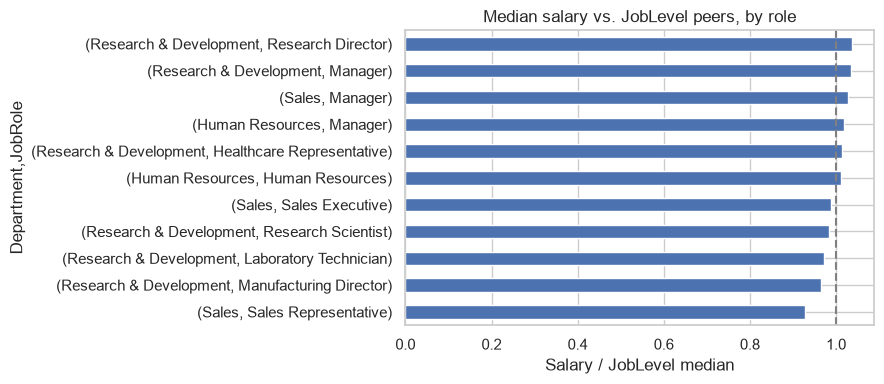

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
sal = df.groupby(["Department", "JobRole"], observed=True).SalaryRatioToLevel.median().sort_values()
sal.plot.barh(ax=ax, color=STAY); ax.axvline(1, ls="--", color="grey")
ax.set_title("Median salary vs. JobLevel peers, by role"); ax.set_xlabel("Salary / JobLevel median")
plt.tight_layout(); plt.savefig(FIG_DIR / "07_salary_positioning.png", dpi=150); plt.show()

## 4. Employee satisfaction & working conditions
**Q4:** Is overtime associated with higher attrition? **Q5:** satisfaction and work-life balance.

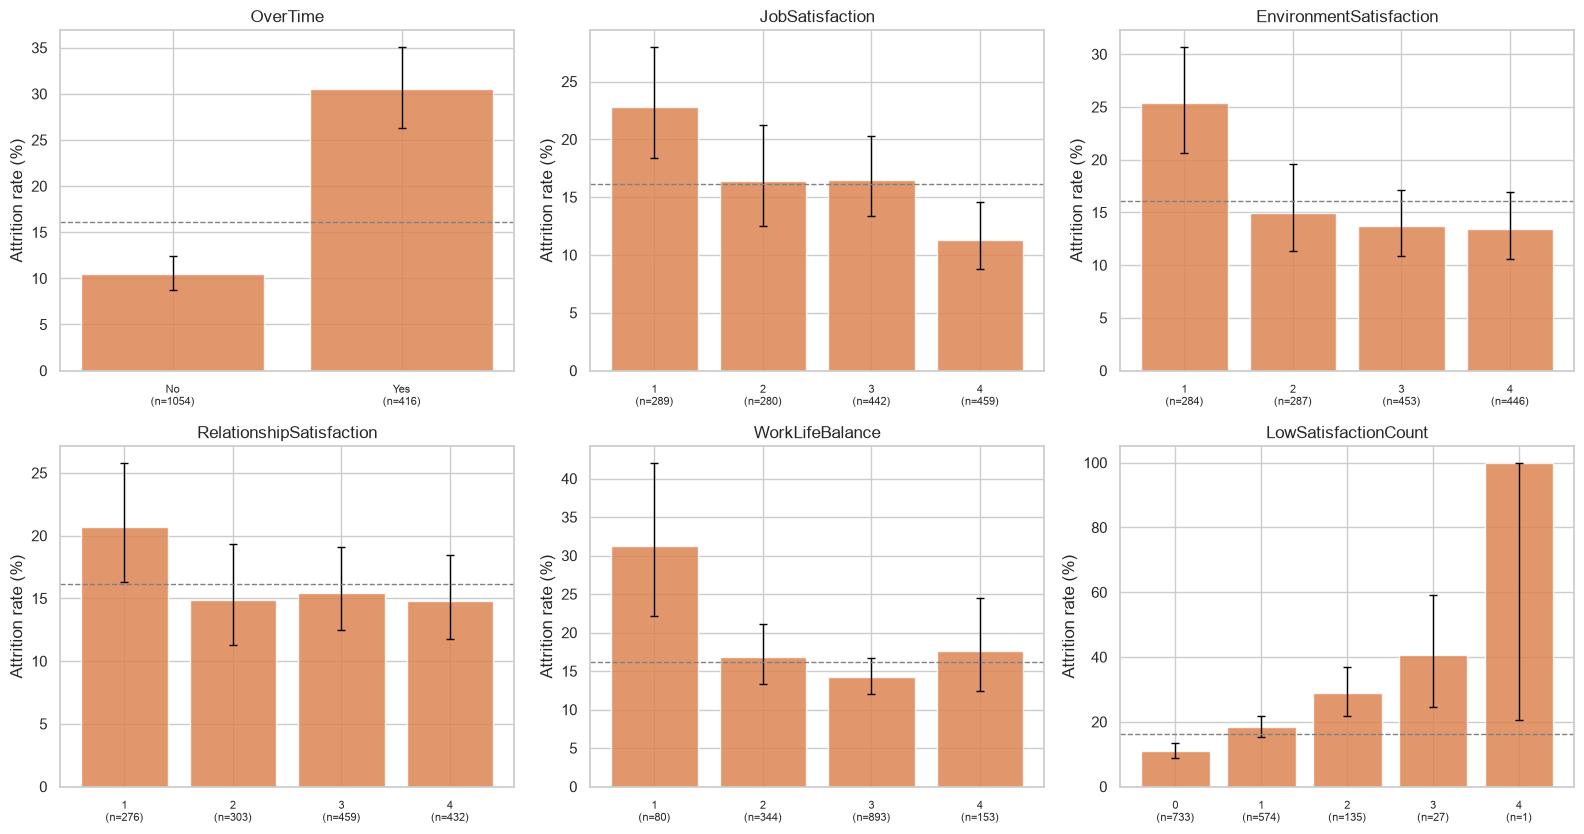

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.flat, ["OverTime", "JobSatisfaction", "EnvironmentSatisfaction",
                               "RelationshipSatisfaction", "WorkLifeBalance", "LowSatisfactionCount"]):
    rate_plot(col, ax, order=sorted(df[col].unique()))
plt.tight_layout(); plt.savefig(FIG_DIR / "08_satisfaction_conditions.png", dpi=150); plt.show()

In [12]:
# Overtime: effect size and significance
ot = rate_table(df, "OverTime", ["Yes", "No"])
chi2, p, v = cramers_v("OverTime")
print(f"OT rate {ot.loc['Yes','rate']:.1%} vs no-OT {ot.loc['No','rate']:.1%}  "
      f"-> risk ratio {ot.loc['Yes','rate']/ot.loc['No','rate']:.2f}, difference {100*(ot.loc['Yes','rate']-ot.loc['No','rate']):.1f} pp")
print(f"chi2={chi2:.1f}, p={p:.2e}, Cramer's V={v:.3f}")

OT rate 30.5% vs no-OT 10.4%  -> risk ratio 2.93, difference 20.1 pp
chi2=87.6, p=8.16e-21, Cramer's V=0.244


In [13]:
# Controlled comparison: does the overtime gap survive within income bands and tenure bands?
def ot_gap(by):
    g = df.groupby([by, "OverTime"], observed=True).AttritionFlag.agg(["mean", "count"]).unstack()
    out = pd.DataFrame({"n_OT": g[("count", "Yes")], "rate_OT_%": 100 * g[("mean", "Yes")],
                        "n_noOT": g[("count", "No")], "rate_noOT_%": 100 * g[("mean", "No")]})
    out["ratio"] = out["rate_OT_%"] / out["rate_noOT_%"]
    return out.reindex(ORDERS.get(by, out.index)).round(2)
display(ot_gap("IncomeBand"))
ot_gap("TenureBand")

,n_OT,rate_OT_%,n_noOT,rate_noOT_%,ratio
IncomeBand,,,,,
<5k,205,42.93,544,13.79,3.11
5k-10k,126,21.43,314,7.01,3.06
10k-15k,52,17.31,96,11.46,1.51
15k+,33,9.09,100,2.00,4.55


,n_OT,rate_OT_%,n_noOT,rate_noOT_%,ratio
TenureBand,,,,,
New (0-2y),104,50.96,238,20.59,2.48
Early (3-5y),127,28.35,307,7.82,3.63
Mid (6-10y),120,25.83,328,7.32,3.53
Long (11y+),65,10.77,181,7.18,1.50


In [14]:
# Business travel (working condition)
chi2, p, v = cramers_v("BusinessTravel")
print(f"BusinessTravel: chi2={chi2:.1f}, p={p:.2e}, Cramer's V={v:.3f}")
rate_table(df, "BusinessTravel").round(3)

BusinessTravel: chi2=24.2, p=5.61e-06, Cramer's V=0.128


,n,left,rate,ci_low,ci_high
BusinessTravel,,,,,
Non-Travel,150,12,0.080,0.046,0.135
Travel_Rarely,1043,156,0.150,0.129,0.172
Travel_Frequently,277,69,0.249,0.202,0.303


## 5. Career development

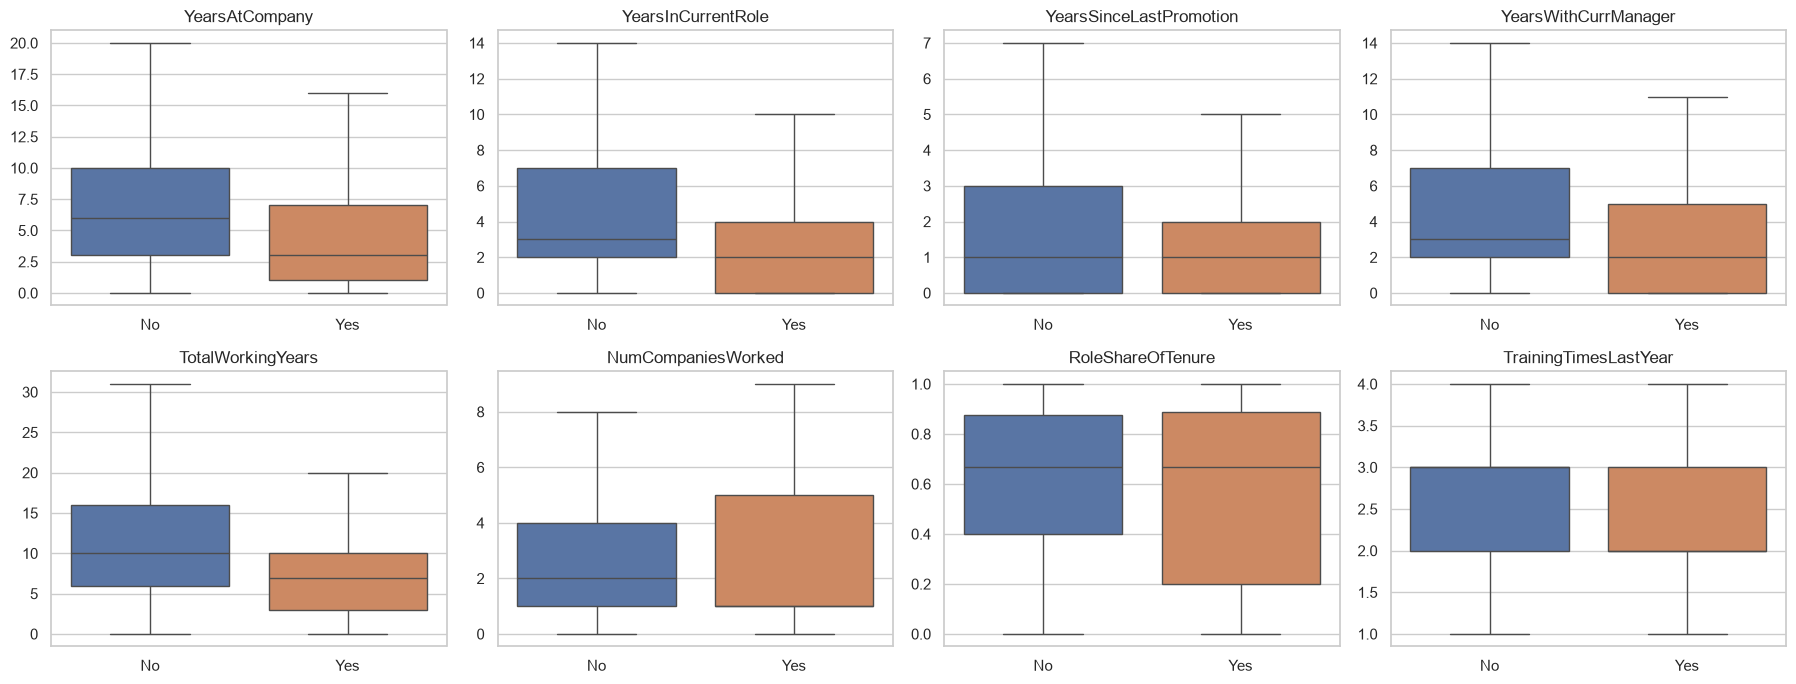

In [15]:
career = ["YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager",
          "TotalWorkingYears", "NumCompaniesWorked", "RoleShareOfTenure", "TrainingTimesLastYear"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.flat, career):
    sns.boxplot(data=df, x="Attrition", y=c, order=["No", "Yes"], hue="Attrition",
                palette={"Yes": LEFT, "No": STAY}, ax=ax, showfliers=False, legend=False)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "09_career_development.png", dpi=150); plt.show()

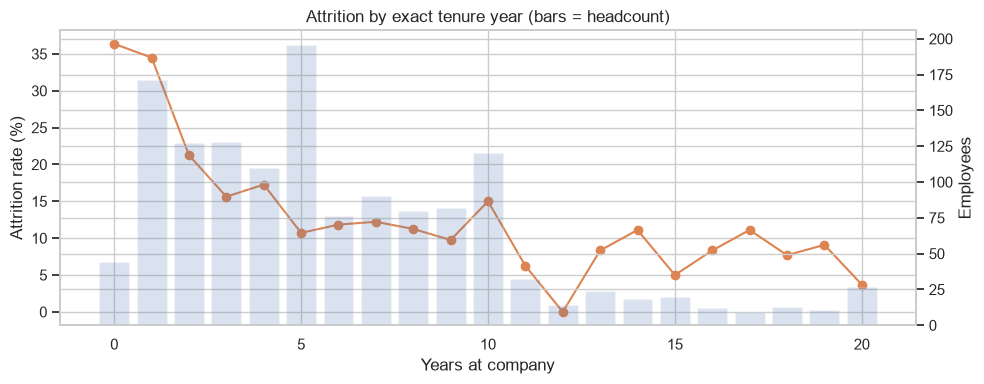

,mean,count,rate_pct
YearsAtCompany,,,
0,0.363636,44,36.4
1,0.345029,171,34.5
2,0.212598,127,21.3
3,0.156250,128,15.6
4,0.172727,110,17.3
5,0.107143,196,10.7


In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
yrs = df[df.YearsAtCompany <= 20].groupby("YearsAtCompany").AttritionFlag.agg(["mean", "count"])
ax.plot(yrs.index, yrs["mean"] * 100, marker="o", color=LEFT)
ax2 = ax.twinx(); ax2.bar(yrs.index, yrs["count"], alpha=.2, color=STAY)
ax.set_xlabel("Years at company"); ax.set_ylabel("Attrition rate (%)"); ax2.set_ylabel("Employees")
ax.set_title("Attrition by exact tenure year (bars = headcount)")
plt.tight_layout(); plt.savefig(FIG_DIR / "10_attrition_by_tenure_year.png", dpi=150); plt.show()
yrs.head(6).assign(rate_pct=lambda d: (100 * d["mean"]).round(1))

## 6. Driver screen — all candidate variables ranked by effect size
Univariate screen: each variable's association with attrition **on its own**.
- Categorical / ordinal-as-category: Cramér's V (0.1 small, 0.3 medium).
- Numeric: |rank-biserial r| from Mann-Whitney (0.1 small, 0.3 medium); sign shows whether leavers are lower (+) or higher (−).

These are **not** model importances and do not adjust for overlaps between variables. Protected attributes are
included for transparency (they will not be model features).

In [17]:
cat_vars = ["OverTime", "JobRole", "MaritalStatus", "BusinessTravel", "Department", "EducationField", "Gender",
            "JobSatisfaction", "EnvironmentSatisfaction", "RelationshipSatisfaction", "WorkLifeBalance",
            "JobInvolvement", "StockOptionLevel", "Education", "PerformanceRating", "JobLevel"]
num_vars = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
            "YearsWithCurrManager", "YearsSinceLastPromotion", "NumCompaniesWorked", "DistanceFromHome",
            "PercentSalaryHike", "TrainingTimesLastYear", "SalaryRatioToLevel", "RoleShareOfTenure",
            "SatisfactionIndex", "DailyRate", "HourlyRate", "MonthlyRate"]
rows = []
for c in cat_vars:
    chi2, p, v = cramers_v(c)
    rows.append({"variable": c, "test": "chi-square", "effect": "Cramer's V", "effect_size": v, "p_value": p})
for c in num_vars:
    p, r, ml, ms = rank_biserial(c)
    rows.append({"variable": c, "test": "Mann-Whitney", "effect": "rank-biserial r", "effect_size": r,
                 "p_value": p, "median_leavers": ml, "median_stayers": ms})
screen = pd.DataFrame(rows)
screen["abs_effect"] = screen.effect_size.abs()
screen["protected"] = screen.variable.isin(["Age", "Gender", "MaritalStatus"])
screen["significant_bonferroni"] = screen.p_value < 0.05 / len(screen)
screen = screen.sort_values("abs_effect", ascending=False).reset_index(drop=True)
screen.to_csv(PROJECT_ROOT / "reports" / "eda_driver_screen.csv", index=False)
screen.round(4)

,variable,test,effect,effect_size,p_value,median_leavers,median_stayers,abs_effect,protected,significant_bonferroni
0,TotalWorkingYears,Mann-Whitney,rank-biserial r,0.3117,0.0000,7.0000,10.0000,0.3117,False,True
1,MonthlyIncome,Mann-Whitney,rank-biserial r,0.3113,0.0000,3202.0000,5204.0000,0.3113,False,True
2,YearsAtCompany,Mann-Whitney,rank-biserial r,0.2979,0.0000,3.0000,6.0000,0.2979,False,True
3,YearsInCurrentRole,Mann-Whitney,rank-biserial r,0.2799,0.0000,2.0000,3.0000,0.2799,False,True
4,YearsWithCurrManager,Mann-Whitney,rank-biserial r,0.2720,0.0000,2.0000,3.0000,0.2720,False,True
5,Age,Mann-Whitney,rank-biserial r,0.2686,0.0000,32.0000,36.0000,0.2686,True,True
6,OverTime,chi-square,Cramer's V,0.2441,0.0000,NaN,NaN,0.2441,False,True
7,JobRole,chi-square,Cramer's V,0.2421,0.0000,NaN,NaN,0.2421,False,True
8,SatisfactionIndex,Mann-Whitney,rank-biserial r,0.2294,0.0000,0.5000,0.5833,0.2294,False,True
9,JobLevel,chi-square,Cramer's V,0.2221,0.0000,NaN,NaN,0.2221,False,True


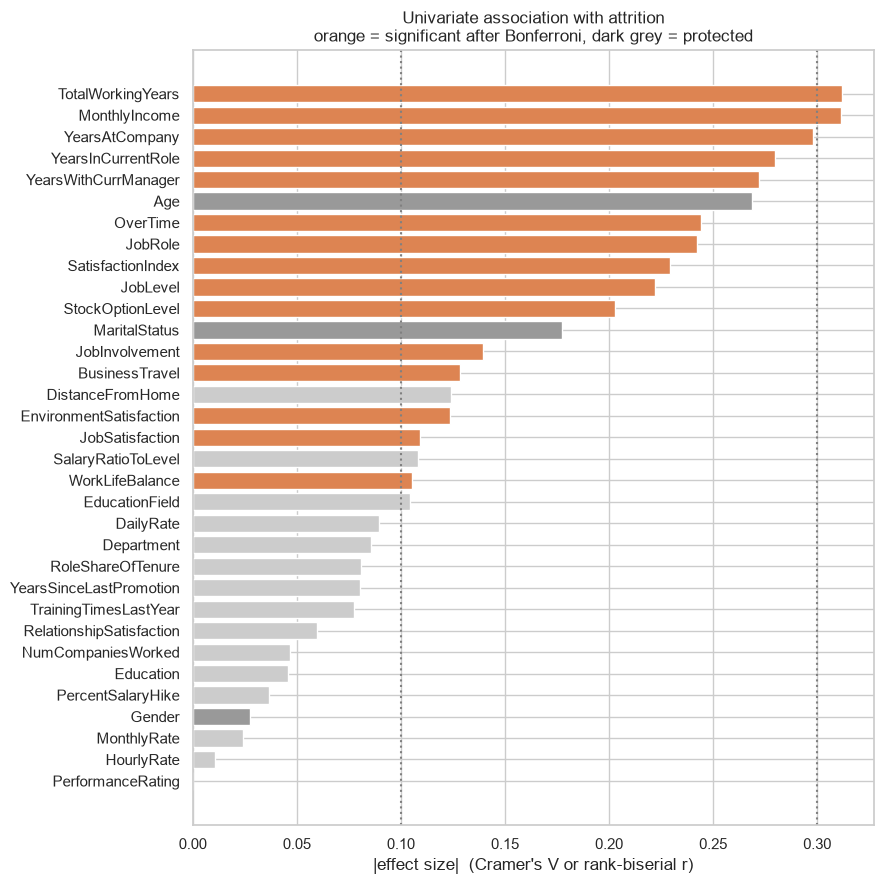

In [18]:
fig, ax = plt.subplots(figsize=(9, 9))
s = screen.iloc[::-1]
colors = ["#999999" if p else (LEFT if sig else "#cccccc") for p, sig in zip(s.protected, s.significant_bonferroni)]
ax.barh(s.variable, s.abs_effect, color=colors)
ax.axvline(0.1, ls=":", color="grey"); ax.axvline(0.3, ls=":", color="grey")
ax.set_xlabel("|effect size|  (Cramer's V or rank-biserial r)")
ax.set_title("Univariate association with attrition\norange = significant after Bonferroni, dark grey = protected")
plt.tight_layout(); plt.savefig(FIG_DIR / "11_driver_screen.png", dpi=150); plt.show()

Interpretation of these outputs: `reports/eda_findings.md`.